[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/02-data-science/06_matplotlib.ipynb)

*Python for Data Science · Notebook 6 of 8*

# Matplotlib

Draw line, bar, scatter, histogram, pie and box charts; add labels, legends and annotations; build multi-panel figures.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A figure is a canvas and axes are the drawings on it. You build a chart in layers, like a painter.

**What interviewers really test here:** Choosing the right chart, and the figure/axes model.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Figure and Axes *(Basics)*
- [ ] 2. Choosing the right chart *(Basics)*
- [ ] 3. From a default chart to a clear one *(Basics)*
- [ ] 4. Labels, legends and styles *(Core)*
- [ ] 5. Several bars and several charts *(Core)*
- [ ] 6. Charts that mislead *(Core)*
- [ ] 7. Working with many panels *(Core)*
- [ ] 8. Scales, uncertainty and saving *(Advanced)*
- [ ] 9. Pointing at what matters *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### What Matplotlib is

**Matplotlib** is Python's foundational plotting library, created by John D. Hunter in 2003 and modelled on MATLAB's plotting. It produces static, animated and interactive charts and can export to PNG, SVG, PDF and more. Pandas' `.plot()` and Seaborn are built on top of it.

### Anatomy of a figure

| Object | What it is |
| --- | --- |
| **Figure** | the whole canvas/window; holds one or more Axes, a suptitle, legends |
| **Axes** | one plotting area with a data coordinate system — the object you draw on |
| **Axis** | the x or y number line of an Axes: limits, ticks, tick labels, scale |
| **Artist** | everything visible: Line2D, Rectangle (bars), Text, PathCollection (scatter), Patch … |



Hierarchy: Figure → Axes → (Axis, Lines, Patches, Texts, Collections). `fig.axes` lists Axes; `ax.lines`, `ax.patches`, `ax.collections`, `ax.texts` list what's drawn — that's how the tests in this topic check your charts.

### Two interfaces

|   | pyplot (state-based) | Object-oriented |
| --- | --- | --- |
| Example | `plt.plot(x); plt.title("t")` | `fig, ax = plt.subplots(); ax.plot(x); ax.set_title("t")` |
| Acts on | the implicit "current" Figure/Axes | the object you name |
| Good for | quick interactive exploration | scripts, functions, multi-panel figures |



Method names differ slightly: `plt.title` ↔ `ax.set_title`, `plt.xlabel` ↔ `ax.set_xlabel`, `plt.xlim` ↔ `ax.set_xlim`.

### Plot types

| Method | Chart | Data |
| --- | --- | --- |
| `plot` | line | ordered x (time) |
| `scatter` | points | two numeric variables (+ size/colour) |
| `bar / barh` | bars | category → number |
| `hist` | histogram | distribution of one variable |
| `boxplot / violinplot` | box / violin | distribution summaries by group |
| `pie` | pie | parts of a whole |
| `errorbar / fill_between` | uncertainty | mean ± error |
| `imshow / pcolormesh` | heat map / image | 2-D grid |
| `stackplot`, `step`, `stem` | area, step, stem | specialised |

### Customisation

- **Colours**: names (`"red"`), hex (`"#0F766E"`), cycle (`"C0"…"C9"`), colormaps for continuous data (`cmap="viridis"`).
- **Lines**: `linestyle` ("-", "--", ":", "-."), `linewidth`, `marker` ("o", "s", "^", "x").
- **Text**: `set_title/xlabel/ylabel`, `text`, `annotate`, `fig.suptitle`.
- **Axes**: `set_xlim/ylim`, `set_xscale("log")`, `set_xticks(positions, labels)`, `invert_yaxis`, `twinx`.
- **Layout**: `plt.subplots(nrows, ncols, sharex, sharey, figsize)`, `fig.tight_layout()` or `layout="constrained"`, `GridSpec` for uneven grids.
- **Global style**: `plt.style.use(...)`, `plt.rcParams[...]`.

### Good chart practice

- Pick the chart for the question (compare → bar; trend → line; relationship → scatter; distribution → histogram/box).
- Bar charts should start at zero; line charts may not need to.
- Label axes with units; title with the takeaway.
- Sort bars by value unless the categories have a natural order.
- Avoid 3-D effects and pies with many slices.
- Use colour sparingly and make it colour-blind friendly (viridis, the default C0–C9 cycle).

---
# Part 2: Lessons, step by step

## Lesson 1: Figure and Axes

*Level: Basics*

Every Matplotlib chart lives in a **Figure** (the whole image) that contains one or more **Axes** (a single plot area with its own x and y axis). Most of your work is calling methods on an Axes.



```python
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))   # width, height in inches
ax.plot([1, 2, 3], [4, 1, 6])
ax.set_title("My first chart")
plt.show()                               # in a script: open the window
```



Matplotlib has two styles: the quick **pyplot** style (`plt.plot`, `plt.title` — acts on "the current Axes") and the **object-oriented** style above. Prefer the OO style: it's explicit, and it's what you need once a figure has several charts. In the animations, the chart appears on the last step.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

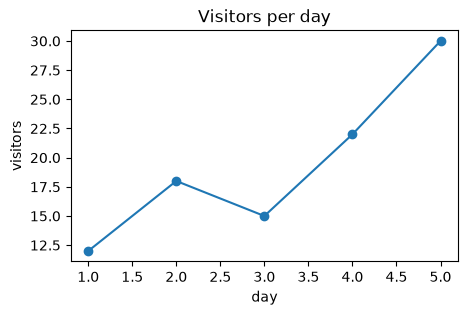

In [2]:
def first_chart():
    fig, ax = plt.subplots(figsize=(5, 3))
    days = [1, 2, 3, 4, 5]
    visitors = [12, 18, 15, 22, 30]
    ax.plot(days, visitors, marker="o")
    ax.set(title="Visitors per day", xlabel="day", ylabel="visitors")


first_chart()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 2: Choosing the right chart

*Level: Basics*

| You want to show… | Chart | Method |
| --- | --- | --- |
| change over time / an ordered x | line | `ax.plot` |
| comparison between categories | bar (horizontal for long names) | `ax.bar`, `ax.barh` |
| relationship between two numbers | scatter | `ax.scatter` |
| distribution of one number | histogram, box plot | `ax.hist`, `ax.boxplot` |
| parts of a whole (few parts) | pie (or a stacked bar) | `ax.pie` |
| uncertainty | error bars, shaded band | `ax.errorbar`, `ax.fill_between` |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

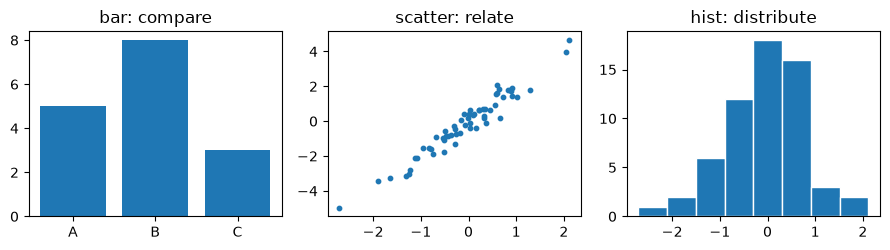

In [3]:
def chart_types():
    fig, axes = plt.subplots(1, 3, figsize=(9, 2.6))
    axes[0].bar(["A", "B", "C"], [5, 8, 3])
    axes[0].set_title("bar: compare")
    rng = np.random.default_rng(1)
    x = rng.normal(0, 1, 60)
    axes[1].scatter(x, x * 2 + rng.normal(0, 0.5, 60), s=10)
    axes[1].set_title("scatter: relate")
    axes[2].hist(x, bins=8, edgecolor="white")
    axes[2].set_title("hist: distribute")
    fig.tight_layout()


chart_types()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q5](#q5), [Q6](#q6), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 3: From a default chart to a clear one

*Level: Basics*

A chart should answer a question at a glance. The chart in the demo goes from default to clear in a few steps:



1. **Sort** the bars by value, unless they have a natural order.
2. **Title with the finding:** "Pune leads sales", not "Sales by city".
3. **Label the units** on the axis, such as "sales (₹ lakh)".
4. **Remove clutter:** top and right borders, a pointless legend.
5. **Highlight** what matters with colour, and grey out the rest.
6. **Label values directly** when there are few of them: `ax.bar_label`.



Every element should earn its place. If you removed it and nothing was lost, leave it out.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

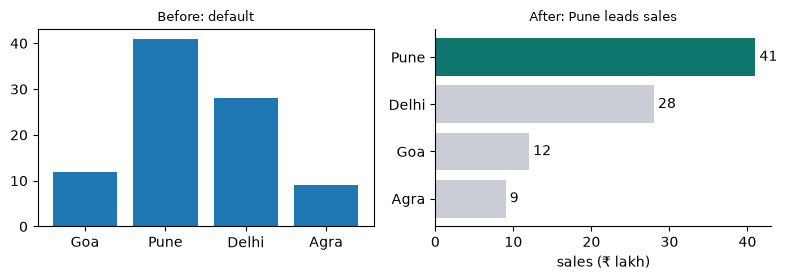

In [4]:
def default_to_clear():
    sales = {"Goa": 12, "Pune": 41, "Delhi": 28, "Agra": 9}
    fig, (before, after) = plt.subplots(1, 2, figsize=(8, 2.9))
    before.bar(list(sales), list(sales.values()))
    before.set_title("Before: default", fontsize=9)
    ordered = sorted(sales.items(), key=lambda kv: kv[1])
    names = [k for k, v in ordered]
    values = [v for k, v in ordered]
    colours = ["#0f766e" if k == "Pune" else "#c9ced6" for k in names]
    bars = after.barh(names, values, color=colours)
    after.bar_label(bars, padding=3)
    after.set_title("After: Pune leads sales", fontsize=9)
    after.set_xlabel("sales (₹ lakh)")
    after.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()


default_to_clear()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q7](#q7), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 4: Labels, legends and styles

*Level: Core*

```python
ax.plot(x, a, label="2024", color="C0", linestyle="-", marker="o", linewidth=2)
ax.plot(x, b, label="2023", color="gray", linestyle="--")
ax.set(title="Sales", xlabel="month", ylabel="₹ (thousands)", ylim=(0, 100))
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
ax.annotate("launch", xy=(3, 80), xytext=(1, 90), arrowprops={"arrowstyle": "->"})
```



Every chart needs a clear title, axis labels with units, and a legend when there's more than one series. Colours `"C0"`, `"C1"` … are the default palette.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

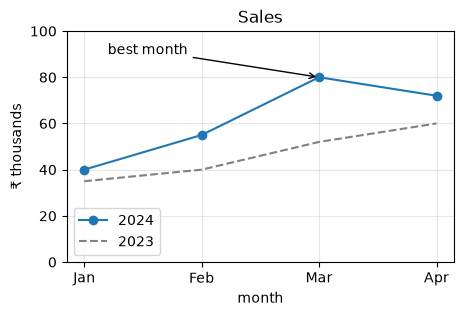

In [5]:
def labels_demo():
    months = ["Jan", "Feb", "Mar", "Apr"]
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(months, [40, 55, 80, 72], marker="o", label="2024")
    ax.plot(months, [35, 40, 52, 60], linestyle="--", color="gray", label="2023")
    ax.set(title="Sales", xlabel="month", ylabel="₹ thousands", ylim=(0, 100))
    ax.annotate("best month", xy=(2, 80), xytext=(0.2, 90), arrowprops={"arrowstyle": "->"})
    ax.legend()
    ax.grid(True, alpha=0.3)


labels_demo()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q8](#q8), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 5: Several bars and several charts

*Level: Core*

**Grouped bars**: shift each series left/right by half a bar width. **Stacked bars**: pass `bottom=` the previous series.



**Several charts in one figure**:



```python
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)
for ax, (name, values) in zip(axes.flat, data.items()):
    ax.plot(values); ax.set_title(name)
fig.tight_layout()                     # stop labels overlapping
right = ax.twinx()                     # second y axis on the same chart
```

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

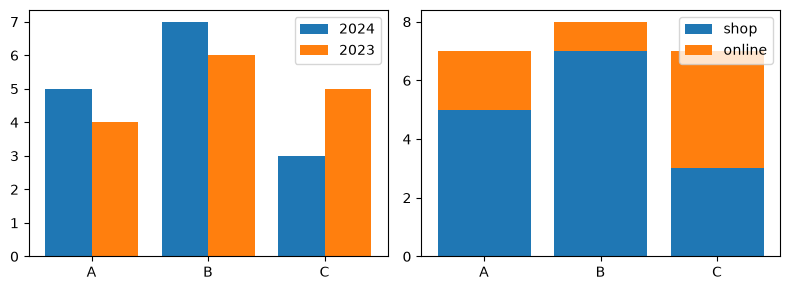

In [6]:
def grouped_demo():
    names = ["A", "B", "C"]
    x = np.arange(len(names))
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
    left.bar(x - 0.2, [5, 7, 3], width=0.4, label="2024")
    left.bar(x + 0.2, [4, 6, 5], width=0.4, label="2023")
    left.set_xticks(x, names)
    left.legend()
    right.bar(names, [5, 7, 3], label="shop")
    right.bar(names, [2, 1, 4], bottom=[5, 7, 3], label="online")
    right.legend()
    fig.tight_layout()


grouped_demo()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q13](#q13), [Q12](#q12), [Q19](#q19), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 6: Charts that mislead

*Level: Core*

The same honest numbers can tell a false story. Learn to spot and avoid these:



| Trick | Effect | Do this |
| --- | --- | --- |
| Bar axis not starting at 0 | a 2% gap looks huge | start bars at 0 |
| Two y axes | any two lines can seem to move together | use two panels, or index both to 100 |
| Chart areas for values | doubling the radius quadruples the area | use length |
| Picking a date range | a fall can be made to look like growth | show the full context |
| Pie with many slices | angles are hard to compare | sorted bars |
| Averages only | hides spread and outliers | show the points, or a box plot |



The demo plots 98 vs 100 twice. With a cut axis, one bar looks many times smaller than the other. With an axis from 0, they're almost equal, which is the truth.



**Exception:** line charts don't need to start at 0, since they show change rather than size.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

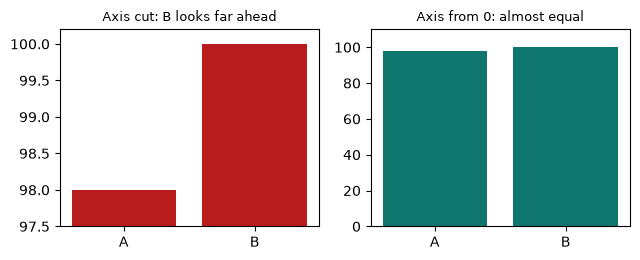

In [7]:
def truncated_axis():
    names, values = ["A", "B"], [98, 100]
    fig, (cut, honest) = plt.subplots(1, 2, figsize=(6.5, 2.7))
    cut.bar(names, values, color="#b91c1c")
    cut.set_ylim(97.5, 100.2)
    cut.set_title("Axis cut: B looks far ahead", fontsize=9)
    honest.bar(names, values, color="#0f766e")
    honest.set_ylim(0, 110)
    honest.set_title("Axis from 0: almost equal", fontsize=9)
    fig.tight_layout()


truncated_axis()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 7: Working with many panels

*Level: Core*

`plt.subplots` returns a figure and `axes`. The shape of `axes` changes, and that's a common source of errors:



| Call | axes is | Access with |
| --- | --- | --- |
| `plt.subplots()` | one Axes | `ax.plot(...)` |
| `plt.subplots(1, 3)` | array of shape (3,) | `axes[0]` |
| `plt.subplots(2, 3)` | array of shape (2, 3) | `axes[1, 2]`, or loop over `axes.flat` |



#### Small multiples



One panel per category, on **shared axes**, often beats many lines on one chart. Use `sharex=True, sharey=True` so panels can be compared at a glance. Without shared axes, a small value can look just as large as a big one.



Finish with `fig.tight_layout()` to stop labels overlapping.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

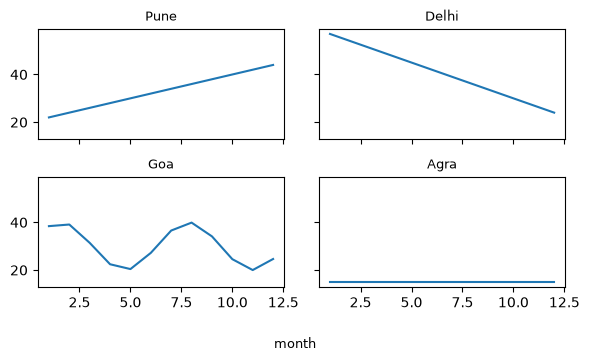

In [8]:
def small_multiples():
    months = np.arange(1, 13)
    cities = {"Pune": 20 + 2 * months, "Delhi": 60 - 3 * months, "Goa": 30 + 10 * np.sin(months), "Agra": 15 + 0 * months}
    fig, axes = plt.subplots(2, 2, figsize=(6, 3.6), sharex=True, sharey=True)
    for ax, (city, values) in zip(axes.flat, cities.items()):
        ax.plot(months, values)
        ax.set_title(city, fontsize=9)
    fig.supxlabel("month", fontsize=9)
    fig.tight_layout()


small_multiples()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 8: Scales, uncertainty and saving

*Level: Advanced*

- **Log scale** (`ax.set_yscale("log")`) for values spanning several orders of magnitude.
- **Error bars** (`ax.errorbar`) and **bands** (`ax.fill_between`) show uncertainty.
- **Saving**: `fig.savefig("chart.png", dpi=200, bbox_inches="tight")`; use `.svg` or `.pdf` for sharp vector output.
- **Styles**: `plt.style.use("ggplot")`, or set defaults with `plt.rcParams["font.size"] = 12`.
- **Pandas shortcut**: `df.plot(x="month", y="sales", kind="bar")` uses Matplotlib underneath and returns the Axes.



**⚠️ Watch out:** Close figures you don't need (`plt.close(fig)`) in loops — each open figure uses memory.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

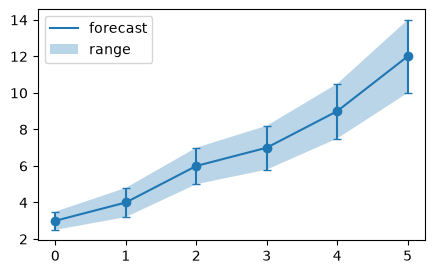

In [9]:
def uncertainty_demo():
    x = np.arange(6)
    mean = np.array([3, 4, 6, 7, 9, 12])
    spread = np.array([0.5, 0.8, 1.0, 1.2, 1.5, 2.0])
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, mean, color="C0", label="forecast")
    ax.fill_between(x, mean - spread, mean + spread, alpha=0.3, label="range")
    ax.errorbar(x, mean, yerr=spread, fmt="o", color="C0", capsize=3)
    ax.legend()


uncertainty_demo()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q16](#q16), [Q17](#q17), [Q10](#q10), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 9: Pointing at what matters

*Level: Advanced*

Guide the reader's eye:



| Tool | Use |
| --- | --- |
| `ax.annotate("Launch", xy=(x, y), xytext=(a, b), arrowprops={...})` | explain one point |
| `ax.axhline(100, ls="--")`, `ax.axvline(...)` | a target or an event |
| `ax.axvspan(a, b, alpha=0.2)` | shade a period |
| `ax.fill_between(x, low, high, alpha=0.2)` | show uncertainty |
| `ax.text(x, y, "label")` | label a line directly, instead of a legend |



#### Colour choices



- **Categories:** distinct colours, at most about 6–8 (`tab10`).
- **Ordered values:** one colour from light to dark (`viridis`).
- **Above or below a middle:** two colours (`coolwarm`, with the centre at 0).
- Don't rely on red vs green alone, as many people can't tell them apart.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

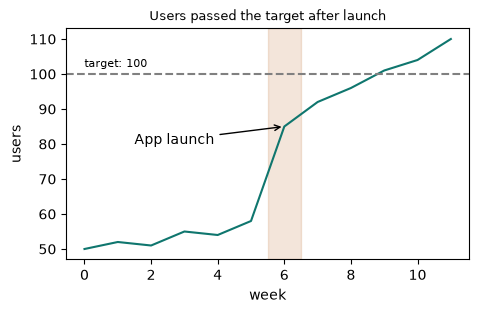

In [10]:
def annotated_story():
    weeks = np.arange(12)
    users = np.array([50, 52, 51, 55, 54, 58, 85, 92, 96, 101, 104, 110])
    fig, ax = plt.subplots(figsize=(5.2, 3))
    ax.plot(weeks, users, color="#0f766e")
    ax.axhline(100, ls="--", color="gray")
    ax.text(0, 102, "target: 100", fontsize=8)
    ax.axvspan(5.5, 6.5, alpha=0.15, color="#b45309")
    ax.annotate("App launch", xy=(6, 85), xytext=(1.5, 80), arrowprops={"arrowstyle": "->"})
    ax.set_xlabel("week")
    ax.set_ylabel("users")
    ax.set_title("Users passed the target after launch", fontsize=9)


annotated_story()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q17](#q17), [Q16](#q16), [Q8](#q8). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [11]:
def bars(ax):
    from matplotlib.patches import Rectangle
    return [p for p in ax.patches if isinstance(p, Rectangle)]


<a id="q1"></a>
### Q1. Line Chart

🟢 Warm-up · *plot · title*

Draw `values` as a line chart titled 'Daily visitors'. Return the Axes.

**Examples**

- `values = [5, 9, 7, 12]` → `"1 line, title 'Daily visitors'"`

In [ ]:
def line_chart(values):
    """
    Draw values as a line chart titled 'Daily visitors'. Return the Axes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(line_chart, [(([5, 9, 7, 12],), "1 line, title 'Daily visitors'")], verify=lambda a, ax: len(ax.lines) == 1 and ax.get_title() == "Daily visitors" and list(ax.lines[0].get_ydata()) == a[0])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

pyplot's state machine: `plt.figure`, `plt.plot`, `plt.title`, then grab the current Axes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Object-oriented API: `fig, ax = plt.subplots()`, then call methods on `ax` — explicit and safe with many charts.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** pyplot's state machine: `plt.figure`, `plt.plot`, `plt.title`, then grab the current Axes.

```python
def line_chart(values):
    plt.figure(figsize=(5, 3))
    plt.plot(range(len(values)), values)
    plt.title("Daily visitors")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Object-oriented API: `fig, ax = plt.subplots()`, then call methods on `ax` — explicit and safe with many charts.

```python
def line_chart(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(values)
    ax.set_title("Daily visitors")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: pyplot's state machine: `plt.figure`, `plt.plot`, `plt.title`, then grab the current Axes. That costs O(n) time and O(n) space."

"I can do better: Object-oriented API: `fig, ax = plt.subplots()`, then call methods on `ax` — explicit and safe with many charts. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/line-chart)

<a id="q2"></a>
### Q2. Two Lines With a Legend

🟢 Warm-up · *label · legend*

Plot two series on the same Axes with labels 'this year' and 'last year' and show a legend.

**Examples**

- `this_year = [3, 5, 4], last_year = [2, 4, 6]` → `'2 lines and a legend'`

In [ ]:
def two_lines(this_year, last_year):
    """
    Plot two series on the same Axes with labels 'this year' and 'last year' and
    show a legend.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_lines, [(([3, 5, 4], [2, 4, 6]), "2 lines and a legend")], verify=lambda a, ax: len(ax.lines) == 2 and ax.get_legend() is not None and [t.get_text() for t in ax.get_legend().get_texts()] == ["this year", "last year"])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Plot each line and build the legend by passing a list of names afterwards.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Give each line a `label=`; `ax.legend()` collects them.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Plot each line and build the legend by passing a list of names afterwards.

```python
def two_lines(this_year, last_year):
    plt.figure(figsize=(5, 3))
    plt.plot(this_year)
    plt.plot(last_year)
    plt.legend(["this year", "last year"])
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Give each line a `label=`; `ax.legend()` collects them.

```python
def two_lines(this_year, last_year):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(this_year, label="this year")
    ax.plot(last_year, label="last year")
    ax.legend()
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Plot each line and build the legend by passing a list of names afterwards. That costs O(n) time and O(n) space."

"I can do better: Give each line a `label=`; `ax.legend()` collects them. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/two-lines-with-a-legend)

<a id="q3"></a>
### Q3. Bar Chart

🟢 Warm-up · *bar*

Draw one bar per category with the given values.

**Examples**

- `names = ['Jan', 'Feb', 'Mar'], values = [30, 45, 25]` → `'3 bars'`

In [ ]:
def bar_chart(names, values):
    """
    Draw one bar per category with the given values.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bar_chart, [((["Jan", "Feb", "Mar"], [30, 45, 25]), "3 bars")], verify=lambda a, ax: [round(b.get_height()) for b in bars(ax)] == a[1])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Call `plt.bar` once per category in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One `ax.bar(names, values)` call draws them all.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Call `plt.bar` once per category in a loop.

```python
def bar_chart(names, values):
    plt.figure(figsize=(5, 3))
    for i in range(len(names)):
        plt.bar(names[i], values[i], color="C0")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** One `ax.bar(names, values)` call draws them all.

```python
def bar_chart(names, values):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(names, values)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Call `plt.bar` once per category in a loop. That costs O(n) time and O(n) space."

"I can do better: One `ax.bar(names, values)` call draws them all. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/bar-chart)

<a id="q4"></a>
### Q4. Scatter Plot

🟢 Warm-up · *scatter*

Plot height (x) against weight (y) as points, with axis labels 'height' and 'weight'.

**Examples**

- `heights = [150, 160, 170, 180], weights = [50, 58, 65, 80]` → `'4 points, labelled axes'`

In [ ]:
def points(ax):
    return sum(len(c.get_offsets()) for c in ax.collections if hasattr(c, "get_offsets"))

def scatter(heights, weights):
    """
    Plot height (x) against weight (y) as points, with axis labels 'height' and
    'weight'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scatter, [(([150, 160, 170, 180], [50, 58, 65, 80]), "4 points, labelled axes")], verify=lambda a, ax: (points(ax) == 4 or sum(len(l.get_xdata()) for l in ax.lines) == 4) and ax.get_xlabel() == "height" and ax.get_ylabel() == "weight")

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`plt.plot` with marker 'o' and no line, one point at a time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.scatter(x, y)` — one call, and size/colour can encode extra columns.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** `plt.plot` with marker 'o' and no line, one point at a time.

```python
def scatter(heights, weights):
    plt.figure(figsize=(5, 3))
    for h, w in zip(heights, weights):
        plt.plot(h, w, "o", color="C0")
    plt.xlabel("height")
    plt.ylabel("weight")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.scatter(x, y)` — one call, and size/colour can encode extra columns.

```python
def scatter(heights, weights):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.scatter(heights, weights)
    ax.set(xlabel="height", ylabel="weight")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `plt.plot` with marker 'o' and no line, one point at a time. That costs O(n) time and O(n) space."

"I can do better: `ax.scatter(x, y)` — one call, and size/colour can encode extra columns. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/scatter-plot)

<a id="q5"></a>
### Q5. Histogram

🟢 Warm-up · *hist*

Draw a histogram of the values with `bins` equal-width bins.

**Examples**

- `values = [1, 2, 2, 3, 3, 3, 4, 4, 5], bins = 4` → `'4 bars whose heights add up to 9'`

In [ ]:
def histogram(values, bins):
    """
    Draw a histogram of the values with bins equal-width bins.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(histogram, [(([1, 2, 2, 3, 3, 3, 4, 4, 5], 4), "4 bars whose heights add up to 9")], verify=lambda a, ax: len(bars(ax)) == a[1] and round(sum(b.get_height() for b in bars(ax))) == len(a[0]))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the bin edges and counts by hand, then draw bars.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.hist(values, bins=bins)` counts and draws.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute the bin edges and counts by hand, then draw bars.

```python
def histogram(values, bins):
    lo, hi = min(values), max(values)
    width = (hi - lo) / bins
    counts = [0] * bins
    for v in values:
        i = min(int((v - lo) / width), bins - 1)
        counts[i] += 1
    plt.figure(figsize=(5, 3))
    plt.bar([lo + width * (i + 0.5) for i in range(bins)], counts, width=width, edgecolor="white")
    return plt.gca()
```

**Cost:** O(n · bins) time, O(bins) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.hist(values, bins=bins)` counts and draws.

```python
def histogram(values, bins):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.hist(values, bins=bins, edgecolor="white")
    return ax
```

**Cost:** O(n) time, O(bins) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the bin edges and counts by hand, then draw bars. That costs O(n · bins) time and O(bins) space."

"I can do better: `ax.hist(values, bins=bins)` counts and draws. That's O(n) time and O(bins) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/histogram)

<a id="q6"></a>
### Q6. Pie Chart With Percentages

🟢 Warm-up · *pie · autopct*

Draw a pie chart of the parts with labels and percentage text on each slice.

**Examples**

- `names = ['rent', 'food', 'fun'], parts = [50, 30, 20]` → `'3 slices with percentage labels'`

In [ ]:
def pie(names, parts):
    """
    Draw a pie chart of the parts with labels and percentage text on each slice.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pie, [((["rent", "food", "fun"], [50, 30, 20]), "3 slices with percentage labels")], verify=lambda a, ax: len(ax.patches) == 3 and any("%" in t.get_text() for t in ax.texts))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each percentage and pass the formatted labels yourself.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.pie(parts, labels=names, autopct='%1.0f%%')`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute each percentage and pass the formatted labels yourself.

```python
def pie(names, parts):
    total = sum(parts)
    labels = [f"{n} ({p / total * 100:.0f}%)" for n, p in zip(names, parts)]
    plt.figure(figsize=(5, 3))
    plt.pie(parts, labels=labels)
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.pie(parts, labels=names, autopct='%1.0f%%')`.

```python
def pie(names, parts):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.pie(parts, labels=names, autopct="%1.0f%%")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each percentage and pass the formatted labels yourself. That costs O(n) time and O(n) space."

"I can do better: `ax.pie(parts, labels=names, autopct='%1.0f%%')`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/pie-chart-with-percentages)

<a id="q7"></a>
### Q7. Labels and Limits

🟢 Warm-up · *ax.set*

Plot the values and set title 'Temperature', x label 'hour', y label '°C' and y-axis limits 0–40.

**Examples**

- `values = [22, 25, 31, 28]` → `'labelled chart with y from 0 to 40'`

In [ ]:
def labelled(values):
    """
    Plot the values and set title 'Temperature', x label 'hour', y label '°C'
    and y-axis limits 0–40.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(labelled, [(([22, 25, 31, 28],), "labelled chart with y from 0 to 40")], verify=lambda a, ax: (ax.get_title(), ax.get_xlabel(), ax.get_ylabel(), tuple(ax.get_ylim())) == ("Temperature", "hour", "°C", (0.0, 40.0)))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Separate pyplot calls for each setting.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One `ax.set(...)` call sets several properties.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Separate pyplot calls for each setting.

```python
def labelled(values):
    plt.figure(figsize=(5, 3))
    plt.plot(values)
    plt.title("Temperature")
    plt.xlabel("hour")
    plt.ylabel("°C")
    plt.ylim(0, 40)
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** One `ax.set(...)` call sets several properties.

```python
def labelled(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(values)
    ax.set(title="Temperature", xlabel="hour", ylabel="°C", ylim=(0, 40))
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Separate pyplot calls for each setting. That costs O(n) time and O(n) space."

"I can do better: One `ax.set(...)` call sets several properties. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/labels-and-limits)

<a id="q8"></a>
### Q8. Markers and Line Styles

🟢 Warm-up · *Format options*

Plot the values with circle markers and a dashed red line.

**Examples**

- `values = [1, 4, 2]` → `"a dashed red line with 'o' markers"`

In [ ]:
def styled(values):
    """
    Plot the values with circle markers and a dashed red line.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(styled, [(([1, 4, 2],), "a dashed red line with 'o' markers")], verify=lambda a, ax: ax.lines[0].get_marker() == "o" and ax.lines[0].get_linestyle() == "--")

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A format string `'ro--'` (colour, marker, style in one code).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Named keyword arguments — easier to read and to change.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** A format string `'ro--'` (colour, marker, style in one code).

```python
def styled(values):
    plt.figure(figsize=(5, 3))
    plt.plot(values, "ro--")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Named keyword arguments — easier to read and to change.

```python
def styled(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(values, color="red", marker="o", linestyle="--")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A format string `'ro--'` (colour, marker, style in one code). That costs O(n) time and O(n) space."

"I can do better: Named keyword arguments — easier to read and to change. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/markers-and-line-styles)

<a id="q9"></a>
### Q9. Logarithmic Scale

🟢 Warm-up · *set\_yscale('log')*

Plot fast-growing values on a log-scale y axis.

**Examples**

- `values = [1, 10, 100, 1000]` → `'a line on a log y axis'`

In [ ]:
def log_scale(values):
    """
    Plot fast-growing values on a log-scale y axis.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_scale, [(([1, 10, 100, 1000],), "a line on a log y axis")], verify=lambda a, ax: ax.get_yscale() == "log")

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Plot log10 of every value instead, and relabel by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.set_yscale('log')` keeps the real values and spaces the axis by powers of 10.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Plot log10 of every value instead, and relabel by hand.

```python
def log_scale(values):
    plt.figure(figsize=(5, 3))
    plt.plot([np.log10(v) for v in values])
    plt.yscale("log")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.set_yscale('log')` keeps the real values and spaces the axis by powers of 10.

```python
def log_scale(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(values)
    ax.set_yscale("log")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Plot log10 of every value instead, and relabel by hand. That costs O(n) time and O(n) space."

"I can do better: `ax.set_yscale('log')` keeps the real values and spaces the axis by powers of 10. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/logarithmic-scale)

<a id="q10"></a>
### Q10. Save a Chart as PNG

🟢 Warm-up · *savefig*

Draw a bar chart and return its PNG image bytes (as you'd write to a file).

**Examples**

- `values = [3, 1, 2]` → `'PNG bytes'`

In [ ]:
import io

def png_bytes(values):
    """
    Draw a bar chart and return its PNG image bytes (as you'd write to a file).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(png_bytes, [(([3, 1, 2],), "PNG bytes")], verify=lambda a, data: isinstance(data, bytes) and data[:4] == b"\x89PNG")

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Save to a temporary file on disk and read it back.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`fig.savefig(buffer, format='png')` into an in-memory `io.BytesIO`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Save to a temporary file on disk and read it back.

```python
def png_bytes(values):
    import os
    import tempfile
    plt.figure(figsize=(5, 3))
    plt.bar(range(len(values)), values)
    path = os.path.join(tempfile.mkdtemp(), "chart.png")
    plt.savefig(path)
    with open(path, "rb") as f:
        data = f.read()
    return data
```

**Cost:** O(pixels) time, O(pixels) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `fig.savefig(buffer, format='png')` into an in-memory `io.BytesIO`.

```python
def png_bytes(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(range(len(values)), values)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=100, bbox_inches="tight")
    return buffer.getvalue()
```

**Cost:** O(pixels) time, O(pixels) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Save to a temporary file on disk and read it back. That costs O(pixels) time and O(pixels) space."

"I can do better: `fig.savefig(buffer, format='png')` into an in-memory `io.BytesIO`. That's O(pixels) time and O(pixels) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/save-a-chart-as-png)

<a id="q11"></a>
### Q11. Sorted Horizontal Bars

🟡 Interview standard · *barh + sorting*

Draw horizontal bars sorted so the largest value is at the top.

**Examples**

- `names = ['a', 'b', 'c'], values = [5, 9, 2]` → `'3 bars, widths 2, 5, 9 from bottom to top'`

In [ ]:
def sorted_bars(names, values):
    """
    Draw horizontal bars sorted so the largest value is at the top.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sorted_bars, [((["a", "b", "c"], [5, 9, 2]), "3 bars, widths 2, 5, 9 from bottom to top")], verify=lambda a, ax: [round(b.get_width()) for b in bars(ax)] == sorted(a[1]))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort with a manual selection sort, then draw each bar.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sort once with `sorted(zip(...))` and pass both lists to `ax.barh`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sort with a manual selection sort, then draw each bar.

```python
def sorted_bars(names, values):
    pairs = list(zip(values, names))
    for i in range(len(pairs)):
        for j in range(i + 1, len(pairs)):
            if pairs[j][0] < pairs[i][0]:
                pairs[i], pairs[j] = pairs[j], pairs[i]
    plt.figure(figsize=(5, 3))
    for v, n in pairs:
        plt.barh(n, v, color="C0")
    return plt.gca()
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Sort once with `sorted(zip(...))` and pass both lists to `ax.barh`.

```python
def sorted_bars(names, values):
    ordered = sorted(zip(values, names))
    widths, labels = zip(*ordered)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.barh(labels, widths)
    return ax
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort with a manual selection sort, then draw each bar. That costs O(n²) time and O(n) space."

"I can do better: Sort once with `sorted(zip(...))` and pass both lists to `ax.barh`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/sorted-horizontal-bars)

<a id="q12"></a>
### Q12. Two Charts Side by Side

🟡 Interview standard · *subplots(1, 2)*

Draw a line chart and a bar chart of the same values next to each other in one figure. Return the Figure.

**Examples**

- `values = [4, 7, 5]` → `'a figure with 2 Axes'`

In [ ]:
def side_by_side(values):
    """
    Draw a line chart and a bar chart of the same values next to each other in
    one figure. Return the Figure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(side_by_side, [(([4, 7, 5],), "a figure with 2 Axes")], verify=lambda a, fig: len(fig.axes) == 2)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Create the figure, then add each panel with `plt.subplot(1, 2, i)`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`fig, (left, right) = plt.subplots(1, 2)` gives both Axes at once.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Create the figure, then add each panel with `plt.subplot(1, 2, i)`.

```python
def side_by_side(values):
    fig = plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1)
    plt.plot(values)
    plt.subplot(1, 2, 2)
    plt.bar(range(len(values)), values)
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `fig, (left, right) = plt.subplots(1, 2)` gives both Axes at once.

```python
def side_by_side(values):
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
    left.plot(values)
    right.bar(range(len(values)), values)
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Create the figure, then add each panel with `plt.subplot(1, 2, i)`. That costs O(n) time and O(n) space."

"I can do better: `fig, (left, right) = plt.subplots(1, 2)` gives both Axes at once. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/two-charts-side-by-side)

<a id="q13"></a>
### Q13. Stacked Bars

🟡 Interview standard · *bottom=*

Draw stacked bars: online sales on top of shop sales for each month.

**Examples**

- `months = ['Jan', 'Feb'], shop = [10, 20], online = [5, 8]` → `'4 bars; online bars start where shop bars end'`

In [ ]:
def stacked(months, shop, online):
    """
    Draw stacked bars: online sales on top of shop sales for each month.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stacked, [((["Jan", "Feb"], [10, 20], [5, 8]), "4 bars; online bars start where shop bars end")], verify=lambda a, ax: len(bars(ax)) == 4 and sorted(round(b.get_y()) for b in bars(ax)) == sorted([0, 0] + a[1]))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Draw each month's two pieces separately with explicit bottoms.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Two `ax.bar` calls; the second uses `bottom=shop`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Draw each month's two pieces separately with explicit bottoms.

```python
def stacked(months, shop, online):
    plt.figure(figsize=(5, 3))
    for i in range(len(months)):
        plt.bar(months[i], shop[i], color="C0")
        plt.bar(months[i], online[i], bottom=shop[i], color="C1")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Two `ax.bar` calls; the second uses `bottom=shop`.

```python
def stacked(months, shop, online):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(months, shop, label="shop")
    ax.bar(months, online, bottom=shop, label="online")
    ax.legend()
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Draw each month's two pieces separately with explicit bottoms. That costs O(n) time and O(n) space."

"I can do better: Two `ax.bar` calls; the second uses `bottom=shop`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/stacked-bars)

<a id="q14"></a>
### Q14. Grouped Bars

🟡 Interview standard · *Offsetting bar positions*

Draw this year's and last year's values side by side for each category.

**Examples**

- `names = ['A', 'B', 'C'], this_year = [5, 7, 3], last_year = [4, 6, 5]` → `'6 bars in 3 pairs'`

In [ ]:
def grouped(names, this_year, last_year):
    """
    Draw this year's and last year's values side by side for each category.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(grouped, [((["A", "B", "C"], [5, 7, 3], [4, 6, 5]), "6 bars in 3 pairs")], verify=lambda a, ax: len(bars(ax)) == 6)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each bar's x position in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Use NumPy positions `x − w/2` and `x + w/2`, then set the tick labels.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute each bar's x position in a loop.

```python
def grouped(names, this_year, last_year):
    plt.figure(figsize=(5, 3))
    for i in range(len(names)):
        plt.bar(i - 0.2, this_year[i], width=0.4, color="C0")
        plt.bar(i + 0.2, last_year[i], width=0.4, color="C1")
    plt.xticks(range(len(names)), names)
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Use NumPy positions `x − w/2` and `x + w/2`, then set the tick labels.

```python
def grouped(names, this_year, last_year):
    x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(x - 0.2, this_year, width=0.4, label="this year")
    ax.bar(x + 0.2, last_year, width=0.4, label="last year")
    ax.set_xticks(x, names)
    ax.legend()
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each bar's x position in a loop. That costs O(n) time and O(n) space."

"I can do better: Use NumPy positions `x − w/2` and `x + w/2`, then set the tick labels. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/grouped-bars)

<a id="q15"></a>
### Q15. Mark the Highest Point

🟡 Interview standard · *annotate*

Plot the values and add an arrow annotation 'max: V' pointing at the highest value.

**Examples**

- `values = [3, 8, 5, 6]` → `"a line with the text 'max: 8'"`

In [ ]:
def mark_max(values):
    """
    Plot the values and add an arrow annotation 'max: V' pointing at the highest
    value.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mark_max, [(([3, 8, 5, 6],), "a line with the text 'max: 8'")], verify=lambda a, ax: any(t.get_text() == f"max: {max(a[0])}" for t in ax.texts))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the max index with a loop; draw the text and arrow separately.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.argmax` + `ax.annotate(text, xy=…, xytext=…, arrowprops=…)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Find the max index with a loop; draw the text and arrow separately.

```python
def mark_max(values):
    best = 0
    for i in range(len(values)):
        if values[i] > values[best]:
            best = i
    plt.figure(figsize=(5, 3))
    plt.plot(values)
    plt.text(best, values[best] + 0.5, f"max: {values[best]}")
    plt.plot(best, values[best], "ro")
    return plt.gca()
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.argmax` + `ax.annotate(text, xy=…, xytext=…, arrowprops=…)`.

```python
def mark_max(values):
    i = int(np.argmax(values))
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(values)
    ax.annotate(f"max: {values[i]}", xy=(i, values[i]), xytext=(i, values[i] + 1), arrowprops={"arrowstyle": "->"})
    return ax
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the max index with a loop; draw the text and arrow separately. That costs O(n) time and O(1) space."

"I can do better: `np.argmax` + `ax.annotate(text, xy=…, xytext=…, arrowprops=…)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/mark-the-highest-point)

<a id="q16"></a>
### Q16. Error Bars

🟡 Interview standard · *errorbar*

Plot averages with error bars of the given sizes.

**Examples**

- `means = [10, 12, 9], errors = [1, 2, 1.5]` → `'3 points with vertical error bars'`

In [ ]:
def error_bars(means, errors):
    """
    Plot averages with error bars of the given sizes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(error_bars, [(([10, 12, 9], [1, 2, 1.5]), "3 points with vertical error bars")], verify=lambda a, ax: len(ax.lines) >= 1 and (len(ax.containers) >= 1 or len(ax.lines) >= 4))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Draw each point and a vertical line for its error by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.errorbar(x, means, yerr=errors, fmt='o', capsize=4)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Draw each point and a vertical line for its error by hand.

```python
def error_bars(means, errors):
    plt.figure(figsize=(5, 3))
    for i, (m, e) in enumerate(zip(means, errors)):
        plt.plot([i, i], [m - e, m + e], color="C0")
        plt.plot(i, m, "o", color="C0")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.errorbar(x, means, yerr=errors, fmt='o', capsize=4)`.

```python
def error_bars(means, errors):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.errorbar(range(len(means)), means, yerr=errors, fmt="o", capsize=4)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Draw each point and a vertical line for its error by hand. That costs O(n) time and O(n) space."

"I can do better: `ax.errorbar(x, means, yerr=errors, fmt='o', capsize=4)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/error-bars)

<a id="q17"></a>
### Q17. Shaded Range

🟡 Interview standard · *fill\_between*

Plot a line of averages and shade the band between the low and high values.

**Examples**

- `avg = [5, 6, 7], low = [3, 4, 6], high = [7, 8, 9]` → `'a line with a shaded band'`

In [ ]:
def shaded(avg, low, high):
    """
    Plot a line of averages and shade the band between the low and high values.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shaded, [(([5, 6, 7], [3, 4, 6], [7, 8, 9]), "a line with a shaded band")], verify=lambda a, ax: len(ax.collections) >= 1 or len(ax.lines) >= 3)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Draw the low and high values as two extra lines.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.fill_between(x, low, high, alpha=0.3)` shades the area.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Draw the low and high values as two extra lines.

```python
def shaded(avg, low, high):
    plt.figure(figsize=(5, 3))
    plt.plot(avg)
    plt.plot(low, color="gray", linestyle=":")
    plt.plot(high, color="gray", linestyle=":")
    return plt.gca()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.fill_between(x, low, high, alpha=0.3)` shades the area.

```python
def shaded(avg, low, high):
    x = range(len(avg))
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, avg)
    ax.fill_between(x, low, high, alpha=0.3)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Draw the low and high values as two extra lines. That costs O(n) time and O(n) space."

"I can do better: `ax.fill_between(x, low, high, alpha=0.3)` shades the area. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/shaded-range)

<a id="q18"></a>
### Q18. Box Plot of Groups

🟡 Interview standard · *boxplot*

Draw one box per group (patch\_artist so boxes are filled).

**Examples**

- `groups = [[1, 2, 3, 4, 9], [3, 4, 5, 6, 7]], names = ['A', 'B']` → `'2 filled boxes'`

In [ ]:
def boxes(groups, names):
    """
    Draw one box per group (patch_artist so boxes are filled).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(boxes, [(([[1, 2, 3, 4, 9], [3, 4, 5, 6, 7]], ["A", "B"]), "2 filled boxes")], verify=lambda a, ax: len(ax.patches) == 2)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute quartiles yourself and draw rectangles and lines.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.boxplot(groups, patch_artist=True)` computes median, quartiles, whiskers and outliers.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute quartiles yourself and draw rectangles and lines.

```python
def boxes(groups, names):
    from matplotlib.patches import Rectangle
    fig, ax = plt.subplots(figsize=(5, 3))
    for i, g in enumerate(groups):
        q1, med, q3 = np.percentile(g, [25, 50, 75])
        ax.add_patch(Rectangle((i + 0.75, q1), 0.5, q3 - q1, facecolor="C0", alpha=0.5))
        ax.plot([i + 0.75, i + 1.25], [med, med], color="black")
        ax.plot([i + 1, i + 1], [min(g), q1], color="black")
        ax.plot([i + 1, i + 1], [q3, max(g)], color="black")
    ax.set_xlim(0.5, len(groups) + 0.5)
    ax.set_ylim(0, max(max(g) for g in groups) + 1)
    ax.set_xticks(range(1, len(groups) + 1), names)
    return ax
```

**Cost:** O(n log n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.boxplot(groups, patch_artist=True)` computes median, quartiles, whiskers and outliers.

```python
def boxes(groups, names):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.boxplot(groups, patch_artist=True)
    ax.set_xticks(range(1, len(names) + 1), names)
    return ax
```

**Cost:** O(n log n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute quartiles yourself and draw rectangles and lines. That costs O(n log n) time and O(1) space."

"I can do better: `ax.boxplot(groups, patch_artist=True)` computes median, quartiles, whiskers and outliers. That's O(n log n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/box-plot-of-groups)

<a id="q19"></a>
### Q19. 2 × 2 Small Multiples

🟡 Interview standard · *subplots grid*

Draw each of four series in its own panel of a 2 × 2 grid, titled with its name. Return the Figure.

**Examples**

- `series = {'a': [1, 2], 'b': [2, 1], 'c': [3, 3], 'd': [1, 3]}` → `'a figure with 4 titled Axes'`

In [ ]:
def small_multiples(series):
    """
    Draw each of four series in its own panel of a 2 × 2 grid, titled with its
    name. Return the Figure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(small_multiples, [(({"a": [1, 2], "b": [2, 1], "c": [3, 3], "d": [1, 3]},), "a figure with 4 titled Axes")], verify=lambda a, fig: len(fig.axes) == 4 and sorted(ax.get_title() for ax in fig.axes) == ["a", "b", "c", "d"])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Call `plt.subplot(2, 2, i)` four times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`fig, axes = plt.subplots(2, 2)` and loop over `axes.flat`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Call `plt.subplot(2, 2, i)` four times.

```python
def small_multiples(series):
    fig = plt.figure(figsize=(6, 4))
    i = 1
    for name, values in series.items():
        plt.subplot(2, 2, i)
        plt.plot(values)
        plt.title(name)
        i += 1
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `fig, axes = plt.subplots(2, 2)` and loop over `axes.flat`.

```python
def small_multiples(series):
    fig, axes = plt.subplots(2, 2, figsize=(6, 4), sharex=True, sharey=True)
    for ax, (name, values) in zip(axes.flat, series.items()):
        ax.plot(values)
        ax.set_title(name)
    fig.tight_layout()
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Call `plt.subplot(2, 2, i)` four times. That costs O(n) time and O(n) space."

"I can do better: `fig, axes = plt.subplots(2, 2)` and loop over `axes.flat`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/2-2-small-multiples)

<a id="q20"></a>
### Q20. Two Different Y Scales

🔴 Stretch · *twinx*

Plot revenue (left axis) and number of orders (right axis) on one chart. Return the Figure.

**Examples**

- `revenue = [100, 150, 130], orders = [3, 5, 4]` → `'revenue and orders both visible, each on a readable scale'`

In [ ]:
def two_scales(revenue, orders):
    """
    Plot revenue (left axis) and number of orders (right axis) on one chart.
    Return the Figure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_scales, [(([100, 150, 130], [3, 5, 4]), "revenue and orders both visible, each on a readable scale")], verify=lambda a, fig: sum(len(ax.lines) for ax in fig.axes) == 2)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rescale orders to the revenue range by hand and plot both on one axis.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ax.twinx()` creates a second y axis sharing the same x axis.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Rescale orders to the revenue range by hand and plot both on one axis.

```python
def two_scales(revenue, orders):
    fig = plt.figure(figsize=(5, 3))
    scale = max(revenue) / max(orders)
    plt.plot(revenue, label="revenue")
    plt.plot([o * scale for o in orders], label=f"orders × {scale:.0f}")
    plt.legend()
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ax.twinx()` creates a second y axis sharing the same x axis.

```python
def two_scales(revenue, orders):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(revenue, color="C0")
    ax.set_ylabel("revenue")
    right = ax.twinx()
    right.plot(orders, color="C1")
    right.set_ylabel("orders")
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rescale orders to the revenue range by hand and plot both on one axis. That costs O(n) time and O(n) space."

"I can do better: `ax.twinx()` creates a second y axis sharing the same x axis. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/matplotlib/two-different-y-scales)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Figure vs Axes?</b></summary>

The Figure is the whole canvas; an Axes is one plot area inside it with its own coordinate system. A figure can hold many Axes.

</details>

<details>
<summary><b>2. plt.plot vs ax.plot?</b></summary>

plt.plot draws on pyplot's current Axes (implicit state). ax.plot draws on a specific Axes object you hold. Use the object-oriented form in scripts and multi-panel figures.

</details>

<details>
<summary><b>3. How do you put several charts in one figure?</b></summary>

`fig, axes = plt.subplots(rows, cols)`, then draw on each element of `axes` (use `axes.flat` to loop), and call `fig.tight_layout()`.

</details>

<details>
<summary><b>4. How do you save a chart?</b></summary>

`fig.savefig('name.png', dpi=200, bbox_inches='tight')`. The file format follows the extension (png, svg, pdf, jpg).

</details>

<details>
<summary><b>5. Histogram vs bar chart?</b></summary>

A bar chart compares values of separate categories; a histogram shows how one numeric variable is distributed by counting values in adjacent bins (no gaps).

</details>

<details>
<summary><b>6. How do you show two variables with different units on one chart?</b></summary>

Create a second y axis with `ax.twinx()`, plot the second variable on it, and label both axes. Use it sparingly — it can mislead.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Figure and Axes
- [ ] I can explain: Choosing the right chart
- [ ] I can explain: From a default chart to a clear one
- [ ] I can explain: Labels, legends and styles
- [ ] I can explain: Several bars and several charts
- [ ] I can explain: Charts that mislead
- [ ] I can explain: Working with many panels
- [ ] I can explain: Scales, uncertainty and saving
- [ ] I can explain: Pointing at what matters

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Error Bars
- [ ] [Q17](#q17) Shaded Range
- [ ] [Q18](#q18) Box Plot of Groups
- [ ] [Q19](#q19) 2 × 2 Small Multiples
- [ ] [Q20](#q20) Two Different Y Scales

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.